In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
dir1 = os.path.dirname(os.path.abspath(''))
if not dir1 in sys.path: sys.path.append(dir1)

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.optimize import minimize

from jax import random
from numpyro.distributions import Gamma

from tqdm.auto import tqdm

from utils.plots import *
from utils.signal import *


In [3]:
param_dir = Path('../prior_params')
param_dir.mkdir(exist_ok=True)

data_dir = Path('../../data/aurora/')

train_df_fpath = Path('../dfs/aurora_train_z_df.csv')
df_train = pd.read_csv(train_df_fpath)

print(f'{len(df_train):,} recordings from {df_train.pid.nunique()} people')


7,019 recordings from 253 people


### A priori HR prior

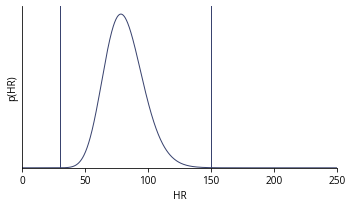

99.999% of density falls between 30 BPM and 150 BPM


In [4]:
min_hr, max_hr = 30, 150

cdf_lo = 1e-5/2
cdf_hi = 1 - cdf_lo

def objective(params):
    min_cdf, max_cdf = Gamma(*params).cdf(np.array([min_hr, max_hr]))
    return (np.log(min_cdf) - np.log(cdf_lo))**2 + (np.log(max_cdf) - np.log(cdf_hi))**2
res = minimize(objective, np.array([10.0,0.1]), method='Nelder-Mead')
alpha_hr, lambd_hr = res.x

x = np.linspace(0, 250, 1000)
y = np.exp(Gamma(alpha_hr, lambd_hr).log_prob(x))

plt.figure(figsize=(5,3))
plt.plot(x, y)
plt.axvline(min_hr)
plt.axvline(max_hr)
plt.xlabel('HR')
plt.ylabel('p(HR)')
plt.yticks([])
plt.ylim(0, None)
plt.show()
print(f'{100-cdf_lo*200:g}% of density falls between {min_hr} BPM and {max_hr} BPM')


In [5]:
np.save(param_dir / 'alpha_hr.npy', alpha_hr)
np.save(param_dir / 'lambd_hr.npy', lambd_hr)


### Load ECG data

In [6]:
z_data = []
for i, row in tqdm(df_train.iterrows(), total=len(df_train)):
    fpath = data_dir / row.waveform_file_path
    df_wav = pd.read_csv(fpath, delimiter='\t')
    t = df_wav.t.values
    assert np.all(np.isclose(np.diff(t), np.diff(t)[0]))
    fs = 1/(t[1]-t[0])
    ecg = df_wav.ekg.values
    r_peaks = find_ecg_peaks(ecg, fs)[0]

    if len(r_peaks) < 2:
        print('uh oh, only', len(r_peaks), 'peaks from',
              row.pid, row.measurement)
        continue

    z_data.append(t[r_peaks])

M_max = max(map(len, z_data))
Z = np.full((len(z_data),M_max), np.nan)
for i, z in enumerate(z_data):
    Z[i,:len(z)] = z


  0%|          | 0/7019 [00:00<?, ?it/s]

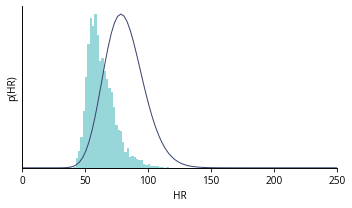

In [7]:
Zp = np.diff(Z, axis=1)

duration = (np.nanmax(Z, axis=1) - np.nanmin(Z, axis=1))
num_pulses = np.sum(~np.isnan(Z), axis=1)
hr = (num_pulses-1) / duration * 60

hr_prior = Gamma(alpha_hr, lambd_hr)

xx = np.linspace(0, 250, 100)
plt.figure(figsize=(5,3))
plt.hist(hr, bins=50, density=True, color=cp[3], alpha=0.5)
plt.ylabel('p(HR)')
plt.xlabel('HR')
plt.yticks([])
plt.twinx()
plt.plot(xx, np.exp(hr_prior.log_prob(xx)), c=cp[0])
plt.yticks([])
plt.ylim(0, None)
plt.show()


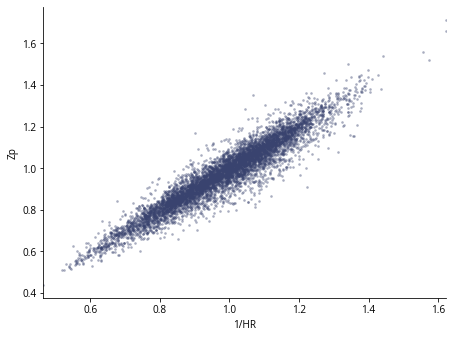

In [8]:
plt.scatter(60/hr, Zp[:,0], s=3, alpha=0.3)
plt.xlabel('1/HR')
plt.ylabel('Zp')
plt.show()


### Normalize pulse intervals by heart rate

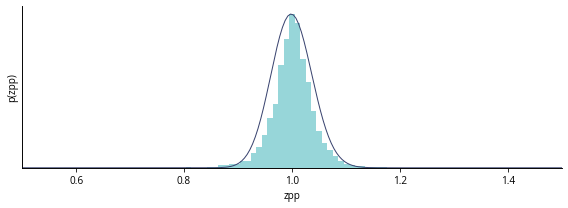

7019 pulses intervals from 7019 recordings


In [9]:
# get hr-normalized pulse intervals
zpp = Zp * (hr[:,None]/60)

# get the middle pulse interval in each signal
ms = np.sum(~np.isnan(zpp), axis=1)//2
zpp_m = np.array([zpp[i,ms[i]] for i in range(len(ms))])

def objective(param):
    log_prob = Gamma(param[0], param[0]).log_prob(zpp_m).sum()
    return -log_prob
res = minimize(objective, np.array([1e3]), method='Nelder-Mead')
alpha_zpp = lambd_zpp = res.x[0]

zpp_prior = Gamma(alpha_zpp, lambd_zpp)

xx = np.linspace(0.5, 1.5, 200)
plt.figure(figsize=(8,3))
plt.hist(zpp_m, bins=np.linspace(0.5, 1.5, 100), color=cp[3], alpha=0.5)
plt.yticks([])
plt.ylabel('p(zpp)')
plt.xlabel('zpp')
plt.twinx()
plt.plot(xx, np.exp(zpp_prior.log_prob(xx)), c=cp[0])
plt.yticks([])
plt.ylim(0, None)
plt.show()

print(zpp_m.size, 'pulses intervals from', Zp.shape[0], 'recordings')


In [10]:
np.save(param_dir / 'alpha_zpp.npy', alpha_zpp)


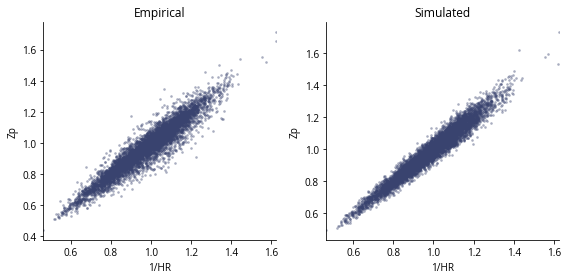

In [11]:
rkey = random.key(0)

zpp_sim = zpp_prior.sample(rkey, Zp.shape)

Zp_sim = zpp_sim * 1/(hr[:,None]/60)

plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.scatter(60/hr, Zp[:,0], s=3, alpha=0.3)
plt.xlabel('1/HR')
plt.ylabel('Zp')
plt.title("Empirical")

plt.subplot(1,2,2)
plt.scatter(60/hr, Zp_sim[:,0], s=3, alpha=0.3)
plt.xlabel('1/HR')
plt.ylabel('Zp')
plt.title("Simulated")
plt.show()
